# Base vs Fine-tuned Comparison — SHROOM-visions
## Thesis: Fine-tuning vs Zero-shot Hallucination Detection

**Purpose**: Run inference with the **unmodified base model** (zero-shot, no LoRA) and compare
against the fine-tuned results already produced by `Finetune_Multimodal_RealData.ipynb`.

**Evaluation metrics** (same as official SHROOM-visions):
- **Span IoU** (primary): character-level intersection-over-union of predicted vs gold spans
- **Spearman ρ**: rank correlation of per-character probability vectors
- **Category F1 (macro)**: hallucination type classification accuracy

**Approach**:
1. Load `Qwen2-VL-2B-Instruct` with **no adapters** and run zero-shot inference.
2. Load fine-tuned results from `ft_predictions/baseline_results.csv` (no re-inference).
3. Compare side-by-side to show the gain from fine-tuning.

In [1]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install',
    'unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git', '--quiet'], check=False)
subprocess.run([sys.executable, '-m', 'pip', 'install',
    '--no-deps', 'trl', 'peft', 'accelerate', 'bitsandbytes', '--quiet'], check=False)
subprocess.run([sys.executable, '-m', 'pip', 'install',
    'qwen-vl-utils', 'transformers>=4.45.0', 'scipy', 'scikit-learn',
    'matplotlib', 'seaborn', '--quiet'], check=False)
print('Installation complete.')

Installation complete.


In [2]:
import json, re, os, io, difflib, random, warnings, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter, defaultdict
from typing import Optional
from scipy.stats import spearmanr
from tqdm.auto import tqdm
import torch
from PIL import Image
from qwen_vl_utils import process_vision_info
from sklearn.model_selection import train_test_split
warnings.filterwarnings('ignore')
print(f'CUDA: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU : {torch.cuda.get_device_name(0)}')

CUDA: True
GPU : NVIDIA A100-SXM4-40GB


In [3]:
# ── Model ────────────────────────────────────────────────────────────────────
MODEL_ID        = 'unsloth/Qwen2-VL-2B-Instruct'
MAX_NEW_TOKENS  = 512
MAX_VAL_SAMPLES = 200   # samples per language; set None for full val set

# ── Val split config (must match Finetune_Multimodal_RealData.ipynb) ─────────
TRAIN_LANGS  = ['en', 'fr', 'it', 'zh']
VAL_FRACTION = 0.10
RANDOM_SEED  = 42

# ── Paths ─────────────────────────────────────────────────────────────────────
from google.colab import drive; drive.mount('/content/drive')
DRIVE_BASE = Path('/content/drive/MyDrive/shroom-visions')
DATA_DIR   = DRIVE_BASE / 'distrib'
IMAGE_DIR  = DRIVE_BASE / 'shroom-vis-images'

# Where this notebook saves base model results
OUTPUT_DIR = DRIVE_BASE / 'base_inference'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Fine-tuned results from Finetune_Multimodal_RealData.ipynb (loaded, not re-run)
BASELINE_CSV = DRIVE_BASE / 'ft_predictions' / 'baseline_results.csv'

# ── Task constants ─────────────────────────────────────────────────────────────
LABEL_ORDER  = ['invention', 'mischaracterization', 'OCR', 'miscounting', 'other']
VALID_LABELS = set(LABEL_ORDER)
LANGUAGES    = ['en', 'fr', 'it', 'zh']
LANG_NAMES   = {'en': 'English', 'fr': 'French', 'it': 'Italian', 'zh': 'Chinese'}

random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); torch.manual_seed(RANDOM_SEED)
print(f'Model       : {MODEL_ID}')
print(f'Output dir  : {OUTPUT_DIR}')
print(f'Finetuned CSV: {BASELINE_CSV}')

Mounted at /content/drive
Model       : unsloth/Qwen2-VL-2B-Instruct
Output dir  : /content/drive/MyDrive/shroom-visions/base_inference
Finetuned CSV: /content/drive/MyDrive/shroom-visions/ft_predictions/baseline_results.csv


---
## 1 — Data: Validation Split

We use the **same 10% held-out split** as the training notebooks so results are directly comparable.

In [4]:
def load_jsonl(path):
    return [json.loads(l) for l in path.read_text(encoding='utf-8').splitlines() if l.strip()]

train_raw = {}
for lang in LANGUAGES:
    train_raw[lang] = load_jsonl(DATA_DIR / f'shroom-vision.train.{lang}.labeled.jsonl')
    print(f'{lang.upper()}: {len(train_raw[lang])} train samples')

EN: 3799 train samples
FR: 3767 train samples
IT: 3746 train samples
ZH: 3790 train samples


In [5]:
def resolve_image_path(image_name, image_dir):
    p = image_dir / image_name
    if p.exists(): return p
    for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']:
        alt = p.with_suffix(ext)
        if alt.exists(): return alt
    return None

INSTRUCTION = """Identify all hallucinated text spans in the vision model's response.
A hallucination is text that is factually incorrect compared to what is actually visible in the image.

Categories:
- invention: entities or facts completely absent from the image
- mischaracterization: visible content described incorrectly
- OCR: text visible in the image is misread or mistranscribed
- miscounting: wrong quantity of visible items
- other: hallucination not fitting the above

Return ONLY a JSON array:
[{"text": "<exact text copied from the response>", "prob": <0.0-1.0>, "label": "<category>"}]
If there are no hallucinations, return: []"""

def build_inference_conv(sample, image_dir):
    img_path = resolve_image_path(sample['image_name'], image_dir)
    if img_path is None: return None
    user_text = f"{INSTRUCTION}\n\nQuestion asked: {sample['prompt']}\n\nVLM response to analyse:\n{sample['response']}"
    return {
        'messages': [{'role': 'user', 'content': [
            {'type': 'image', 'image': str(img_path)},
            {'type': 'text',  'text':  user_text},
        ]}],
        '_id': sample['id'], '_lang': sample.get('language', ''),
        '_response': sample['response'], '_labels': sample.get('labels', []),
    }

# Reproduce identical val split (same random_state as training)
all_val_convs = []
for lang in TRAIN_LANGS:
    samples = train_raw[lang]
    hallu = [s for s in samples if s.get('labels')]
    clean = [s for s in samples if not s.get('labels')]
    _, h_val = train_test_split(hallu, test_size=VAL_FRACTION, random_state=RANDOM_SEED)
    _, c_val = train_test_split(clean, test_size=VAL_FRACTION, random_state=RANDOM_SEED)
    skipped = 0
    for s in h_val + c_val:
        conv = build_inference_conv(s, IMAGE_DIR)
        if conv: all_val_convs.append(conv)
        else: skipped += 1
    print(f'{lang.upper()}: {len(h_val)+len(c_val)} val samples | {skipped} skipped (missing image)')

val_by_lang = defaultdict(list)
for conv in all_val_convs: val_by_lang[conv['_lang']].append(conv)
print(f'\nTotal val conversations: {len(all_val_convs):,}')

EN: 381 val samples | 0 skipped (missing image)
FR: 378 val samples | 0 skipped (missing image)
IT: 375 val samples | 0 skipped (missing image)
ZH: 380 val samples | 0 skipped (missing image)

Total val conversations: 1,514


---
## 2 — Shared Utilities

Inference, parsing, and metric functions shared by both model runs.

In [6]:
LABEL_NORMALISE = {
    'mischaracterisation': 'mischaracterization',
    'ocr_problem': 'OCR', 'ocr problem': 'OCR', 'ocr': 'OCR',
    'fabrication': 'invention', 'count': 'miscounting',
}

def parse_model_output(raw):
    m = re.search(r'\[.*\]', raw, re.DOTALL)
    if not m: return []
    try: spans = json.loads(m.group())
    except: return []
    out = []
    for sp in spans:
        if not isinstance(sp, dict) or 'text' not in sp: continue
        text  = str(sp['text']).strip()
        if not text: continue
        label = LABEL_NORMALISE.get(str(sp.get('label','other')).lower().strip(),
                                     str(sp.get('label','other')).lower().strip())
        if label not in VALID_LABELS: label = 'other'
        prob = max(0.0, min(1.0, float(sp.get('prob', 0.8))))
        out.append({'text': text, 'prob': prob, 'label': label})
    return out

def find_span_pos(response, text):
    if not text: return None
    pos = response.find(text)
    if pos != -1: return pos, pos + len(text)
    pos = response.lower().find(text.lower())
    if pos != -1: return pos, pos + len(text)
    stripped = re.sub(r'[\*\_`]+', '', text).strip()
    if stripped and stripped != text:
        pos = response.lower().find(stripped.lower())
        if pos != -1: return pos, pos + len(stripped)
    if len(text) >= 8:
        tl, rl, tlen = text.lower(), response.lower(), len(text)
        step = max(1, tlen // 4)
        best_r, best_pos = 0.0, 0
        for i in range(0, max(1, len(response)-tlen+1), step):
            r = difflib.SequenceMatcher(None, rl[i:i+tlen], tl).ratio()
            if r > best_r: best_r, best_pos = r, i
        for i in range(max(0, best_pos-step), min(len(response)-tlen+1, best_pos+step+1)):
            r = difflib.SequenceMatcher(None, rl[i:i+tlen], tl).ratio()
            if r > best_r: best_r, best_pos = r, i
        if best_r >= 0.80: return best_pos, best_pos + tlen
    return None

def map_spans_to_positions(response, parsed):
    result, used = [], set()
    for sp in parsed:
        pos = find_span_pos(response, sp['text'])
        if pos is None: continue
        start, end = pos
        if len(set(range(start, end)) & used) > (end-start)*0.5: continue
        result.append({'start': start, 'end': end, 'prob': sp['prob'], 'label': sp['label']})
        used.update(range(start, end))
    return sorted(result, key=lambda x: x['start'])

def run_inference_on_model(conv, model, processor, device):
    msgs = conv['messages']
    text_input = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(msgs)
    inputs = processor(text=[text_input], images=image_inputs, videos=video_inputs,
                       padding=True, return_tensors='pt').to(device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS,
                             do_sample=False, pad_token_id=processor.tokenizer.pad_token_id)
    return processor.batch_decode(out[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True)[0].strip()

def predict_all(convs, model, processor, device, desc=''):
    preds = {}
    for conv in tqdm(convs, desc=desc):
        try:
            raw = run_inference_on_model(conv, model, processor, device)
            preds[conv['_id']] = map_spans_to_positions(conv['_response'], parse_model_output(raw))
        except Exception as e:
            preds[conv['_id']] = []
    return preds

print('Inference utilities ready.')

Inference utilities ready.


In [7]:
def span_iou(pred, gold):
    p = set(i for s in pred for i in range(s['start'], s['end']))
    g = set(i for s in gold for i in range(s['start'], s['end']))
    if not p and not g: return 1.0
    return len(p & g) / len(p | g)

def spearman_rho(pred, gold, resp_len):
    pa = np.zeros(resp_len); ga = np.zeros(resp_len)
    for s in pred:
        for i in range(s['start'], min(s['end'], resp_len)): pa[i] = max(pa[i], s['prob'])
    for s in gold:
        for i in range(s['start'], min(s['end'], resp_len)): ga[i] = max(ga[i], s['prob'])
    if np.allclose(pa, pa[0]) and np.allclose(ga, ga[0]):
        return 1.0 if np.allclose(pa, ga) else 0.0
    rho, _ = spearmanr(pa, ga)
    return float(rho) if not np.isnan(rho) else 0.0

def category_f1(pred, gold, min_iou=0.3):
    tp, fp, fn = Counter(), Counter(), Counter()
    used_gold, used_pred = set(), set()
    for pi, p in enumerate(pred):
        pc = set(range(p['start'], p['end']))
        best_iou, best_gi = 0.0, -1
        for gi, g in enumerate(gold):
            if gi in used_gold: continue
            gc = set(range(g['start'], g['end']))
            iou = len(pc & gc) / max(len(pc | gc), 1)
            if iou > best_iou: best_iou, best_gi = iou, gi
        if best_iou >= min_iou and best_gi != -1:
            if p['label'] == gold[best_gi]['label']: tp[gold[best_gi]['label']] += 1
            else: fp[p['label']] += 1; fn[gold[best_gi]['label']] += 1
            used_gold.add(best_gi); used_pred.add(pi)
    for pi, p in enumerate(pred):
        if pi not in used_pred: fp[p['label']] += 1
    for gi, g in enumerate(gold):
        if gi not in used_gold: fn[g['label']] += 1
    scores = {}
    for cat in LABEL_ORDER:
        prec = tp[cat] / max(tp[cat]+fp[cat], 1)
        rec  = tp[cat] / max(tp[cat]+fn[cat], 1)
        scores[cat] = 2*prec*rec / max(prec+rec, 1e-9)
    scores['macro'] = float(np.mean(list(scores.values())))
    return scores

def evaluate(convs, predictions):
    ious, rhos, all_pred, all_gold = [], [], [], []
    for conv in convs:
        gold = conv['_labels']; pred = predictions.get(conv['_id'], [])
        ious.append(span_iou(pred, gold))
        rhos.append(spearman_rho(pred, gold, len(conv['_response'])))
        all_pred.extend(pred); all_gold.extend(gold)
    return {'mean_iou': float(np.mean(ious)), 'mean_spearman': float(np.nanmean(rhos)),
            'cat_f1': category_f1(all_pred, all_gold), 'n': len(convs)}

def print_metrics(label, results_by_lang, overall):
    print('=' * 65)
    print(f'RESULTS — {label}')
    print('=' * 65)
    for lang in LANGUAGES:
        if lang not in results_by_lang: continue
        m = results_by_lang[lang]
        print(f'[{lang.upper()}]  IoU={m["mean_iou"]:.4f}  Spearman={m["mean_spearman"]:.4f}  CatF1={m["cat_f1"]["macro"]:.4f}')
    print(f'[OVERALL]  IoU={overall["mean_iou"]:.4f}  Spearman={overall["mean_spearman"]:.4f}  CatF1={overall["cat_f1"]["macro"]:.4f}')

print('Metric functions ready.')

Metric functions ready.


---
## 3 — Base Model (Zero-shot) Inference

Load `Qwen2-VL-2B-Instruct` with **no LoRA adapters** and run inference.
This is the control condition — the model has never seen SHROOM-visions training data.

In [8]:
from unsloth import FastVisionModel

print(f'Loading base model: {MODEL_ID}')
model, processor = FastVisionModel.from_pretrained(
    MODEL_ID, load_in_4bit=True, use_gradient_checkpointing=False)
FastVisionModel.for_inference(model)
device = next(model.parameters()).device
print(f'Base model loaded on {device}')
if torch.cuda.is_available():
    print(f'VRAM: {torch.cuda.memory_allocated()/1e9:.1f} / {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: Your Flash Attention 2 installation seems to be broken. Using Xformers instead. No performance changes will be seen.
🦥 Unsloth Zoo will now patch everything to make training faster!
Loading base model: unsloth/Qwen2-VL-2B-Instruct
==((====))==  Unsloth 2026.6.1: Fast Qwen2_Vl patching. Transformers: 5.5.0.
   \\   /|    NVIDIA A100-SXM4-40GB. Num GPUs = 1. Max memory: 39.494 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 8.0. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/572 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/392 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Base model loaded on cuda:0
VRAM: 2.5 / 42.4 GB


In [9]:
base_predictions = {}
for lang, convs in val_by_lang.items():
    convs_eval = convs[:MAX_VAL_SAMPLES] if MAX_VAL_SAMPLES else convs
    print(f'Base model — {lang.upper()} ({len(convs_eval)} samples)...')
    t0 = time.time()
    preds = predict_all(convs_eval, model, processor, device, desc=lang.upper())
    base_predictions.update(preds)
    print(f'  Done in {(time.time()-t0)/60:.1f} min')

print(f'Total base predictions: {len(base_predictions):,}')

Base model — EN (200 samples)...


EN:   0%|          | 0/200 [00:00<?, ?it/s]

Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  Done in 16.3 min
Base model — FR (200 samples)...


FR:   0%|          | 0/200 [00:00<?, ?it/s]

Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

... (3 outputs left out)

  Done in 18.5 min
Base model — ZH (200 samples)...


ZH:   0%|          | 0/200 [00:00<?, ?it/s]

Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  Done in 17.4 min
Total base predictions: 800


In [10]:
METRICS = ['Span IoU', 'Spearman rho', 'Cat F1 (macro)']

base_by_lang = {}
for lang, convs in val_by_lang.items():
    convs_eval = convs[:MAX_VAL_SAMPLES] if MAX_VAL_SAMPLES else convs
    base_by_lang[lang] = evaluate(convs_eval, base_predictions)

all_val_limited = [c for lc in val_by_lang.values()
                   for c in (lc[:MAX_VAL_SAMPLES] if MAX_VAL_SAMPLES else lc)]
base_overall = evaluate(all_val_limited, base_predictions)
print_metrics('Base Model (Zero-shot)', base_by_lang, base_overall)

rows = []
for lang in LANGUAGES:
    if lang not in base_by_lang: continue
    m = base_by_lang[lang]
    row = {'Language': lang.upper(),
           'Span IoU': round(m['mean_iou'], 4),
           'Spearman rho': round(m['mean_spearman'], 4),
           'Cat F1 (macro)': round(m['cat_f1']['macro'], 4)}
    for cat in LABEL_ORDER:
        row[f'F1({cat[:4]})'] = round(m['cat_f1'].get(cat, 0.0), 4)
    rows.append(row)
row_all = {'Language': 'OVERALL',
           'Span IoU': round(base_overall['mean_iou'], 4),
           'Spearman rho': round(base_overall['mean_spearman'], 4),
           'Cat F1 (macro)': round(base_overall['cat_f1']['macro'], 4)}
for cat in LABEL_ORDER:
    row_all[f'F1({cat[:4]})'] = round(base_overall['cat_f1'].get(cat, 0.0), 4)
rows.append(row_all)
base_df = pd.DataFrame(rows)

base_df.to_csv(OUTPUT_DIR / 'base_results.csv', index=False)
print(f'Saved -> {OUTPUT_DIR / "base_results.csv"}')
print(base_df.to_string(index=False))

RESULTS — Base Model (Zero-shot)
[EN]  IoU=0.0910  Spearman=0.0184  CatF1=0.0385
[FR]  IoU=0.1472  Spearman=0.0013  CatF1=0.0410
[IT]  IoU=0.1459  Spearman=0.0022  CatF1=0.0568
[ZH]  IoU=0.1303  Spearman=0.0067  CatF1=0.0721
[OVERALL]  IoU=0.1286  Spearman=0.0072  CatF1=0.0699
Saved -> /content/drive/MyDrive/shroom-visions/base_inference/base_results.csv
Language  Span IoU  Spearman rho  Cat F1 (macro)  F1(inve)  F1(misc)  F1(OCR)  F1(othe)
      EN    0.0910        0.0184          0.0385    0.1253    0.0290   0.0000    0.0290
      FR    0.1472        0.0013          0.0410    0.1588    0.0000   0.0000    0.0408
      IT    0.1459        0.0022          0.0568    0.1574    0.0580   0.0000    0.0299
      ZH    0.1303        0.0067          0.0721    0.1871    0.0943   0.0000    0.0400
 OVERALL    0.1286        0.0072          0.0699    0.1632    0.0701   0.0149    0.0681


---
## 4 — Fine-tuned Results (from `Finetune_Multimodal_RealData.ipynb`)

Load pre-computed fine-tuned results — no re-inference needed.

In [11]:
if not BASELINE_CSV.exists():
    raise FileNotFoundError(
        f'Fine-tuned results not found: {BASELINE_CSV}\n'
        'Run Finetune_Multimodal_RealData.ipynb first to generate it.'
    )

ft_df = pd.read_csv(BASELINE_CSV)
# Normalise Spearman column name in case it was saved with the rho symbol
if 'Spearman \u03c1' in ft_df.columns:
    ft_df = ft_df.rename(columns={'Spearman \u03c1': 'Spearman rho'})

print(f'Loaded fine-tuned results from {BASELINE_CSV}')
print(ft_df.to_string(index=False))

Loaded fine-tuned results from /content/drive/MyDrive/shroom-visions/ft_predictions/baseline_results.csv
Language  Span IoU  Spearman rho  Cat F1 (macro)  F1(inve)  F1(misc)  F1(OCR)  F1(othe)
      EN    0.2493        0.3085          0.2718    0.3384    0.3636   0.1220    0.1887
      FR    0.3386        0.3551          0.3364    0.4747    0.4706   0.2222    0.1463
      IT    0.3271        0.3797          0.2992    0.5073    0.3871   0.0000    0.2462
      ZH    0.3257        0.3565          0.2671    0.4282    0.3522   0.2353    0.0541
 OVERALL    0.3102        0.3500          0.2861    0.4176    0.3624   0.1143    0.1735


---
## 5 — Comparison: Base (Zero-shot) vs Fine-tuned

In [12]:
comparison_rows = []
for _, brow in base_df.iterrows():
    lang = brow['Language']
    ft_row = ft_df[ft_df['Language'] == lang]
    if ft_row.empty: continue
    ft_row = ft_row.iloc[0]
    row = {'Language': lang}
    for m in METRICS:
        bval = float(brow[m]) if m in brow else 0.0
        fval = float(ft_row[m]) if m in ft_row.index else 0.0
        delta = fval - bval
        sign = '+' if delta >= 0 else ''
        row[f'{m} (base)']      = f'{bval:.4f}'
        row[f'{m} (finetuned)'] = f'{fval:.4f}'
        row[f'{m} Δ']           = f'{sign}{delta:.4f}'
    comparison_rows.append(row)

cmp_df = pd.DataFrame(comparison_rows)
print('=' * 80)
print('COMPARISON: Base Model (Zero-shot)  vs  Fine-tuned (Real Data)')
print('=' * 80)
print(cmp_df.to_string(index=False))
cmp_df.to_csv(OUTPUT_DIR / 'comparison_base_vs_finetuned.csv', index=False)
print(f'Saved -> {OUTPUT_DIR / "comparison_base_vs_finetuned.csv"}')

COMPARISON: Base Model (Zero-shot)  vs  Fine-tuned (Real Data)
Language Span IoU (base) Span IoU (finetuned) Span IoU Δ Spearman rho (base) Spearman rho (finetuned) Spearman rho Δ Cat F1 (macro) (base) Cat F1 (macro) (finetuned) Cat F1 (macro) Δ
      EN          0.0910               0.2493    +0.1583              0.0184                   0.3085        +0.2901                0.0385                     0.2718          +0.2333
      FR          0.1472               0.3386    +0.1914              0.0013                   0.3551        +0.3538                0.0410                     0.3364          +0.2954
      IT          0.1459               0.3271    +0.1812              0.0022                   0.3797        +0.3775                0.0568                     0.2992          +0.2424
      ZH          0.1303               0.3257    +0.1954              0.0067                   0.3565        +0.3498                0.0721                     0.2671          +0.1950
 OVERALL          0.12

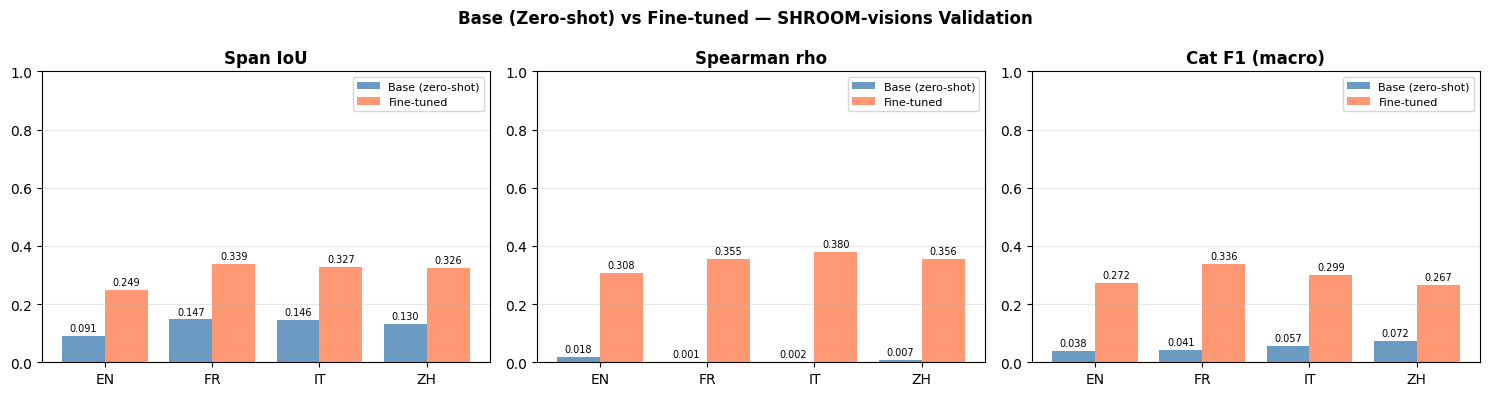

Saved -> /content/drive/MyDrive/shroom-visions/base_inference/comparison_base_vs_finetuned.png


In [13]:
langs_plot = [r['Language'] for r in comparison_rows if r['Language'] != 'OVERALL']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, METRICS):
    base_vals = [float(base_df[base_df['Language'] == l][metric].values[0]) for l in langs_plot]
    ft_vals   = [float(ft_df[ft_df['Language'] == l][metric].values[0]) for l in langs_plot]
    x = np.arange(len(langs_plot))
    ax.bar(x - 0.2, base_vals, 0.4, label='Base (zero-shot)', color='steelblue', alpha=0.8)
    ax.bar(x + 0.2, ft_vals,   0.4, label='Fine-tuned',        color='coral',     alpha=0.8)
    for xi, (bv, fv) in enumerate(zip(base_vals, ft_vals)):
        ax.text(xi - 0.2, bv + 0.01, f'{bv:.3f}', ha='center', va='bottom', fontsize=7)
        ax.text(xi + 0.2, fv + 0.01, f'{fv:.3f}', ha='center', va='bottom', fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(langs_plot)
    ax.set_title(metric, fontweight='bold'); ax.set_ylim(0, 1)
    ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)

plt.suptitle('Base (Zero-shot) vs Fine-tuned — SHROOM-visions Validation', fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'comparison_base_vs_finetuned.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {OUTPUT_DIR / "comparison_base_vs_finetuned.png"}')

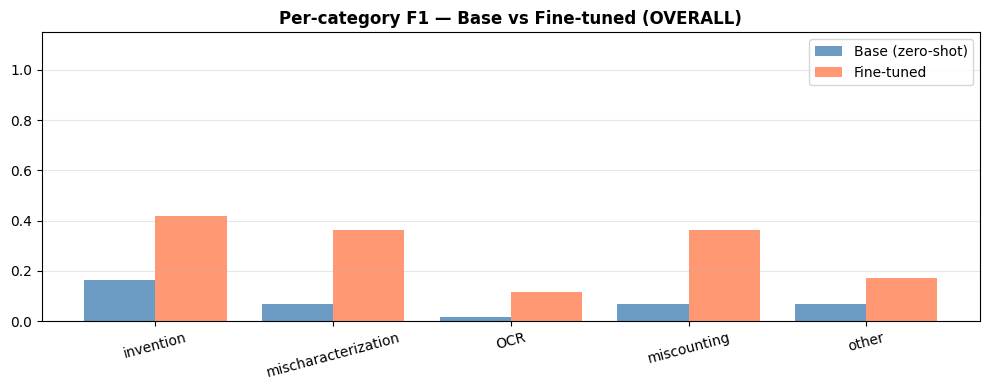

Saved -> /content/drive/MyDrive/shroom-visions/base_inference/comparison_per_category_f1.png


In [14]:
# Per-category F1: base vs finetuned (OVERALL only)
base_overall_row = base_df[base_df['Language'] == 'OVERALL'].iloc[0]
ft_overall_row   = ft_df[ft_df['Language'] == 'OVERALL'].iloc[0]
cat_cols = [f'F1({c[:4]})' for c in LABEL_ORDER]

base_cat = [float(base_overall_row[c]) for c in cat_cols]
ft_cat   = [float(ft_overall_row[c])   for c in cat_cols]

x = np.arange(len(LABEL_ORDER))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, base_cat, 0.4, label='Base (zero-shot)', color='steelblue', alpha=0.8)
ax.bar(x + 0.2, ft_cat,   0.4, label='Fine-tuned',        color='coral',     alpha=0.8)
ax.set_xticks(x); ax.set_xticklabels(LABEL_ORDER, rotation=15)
ax.set_ylim(0, 1.15)
ax.set_title('Per-category F1 — Base vs Fine-tuned (OVERALL)', fontweight='bold')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'comparison_per_category_f1.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {OUTPUT_DIR / "comparison_per_category_f1.png"}')

---
## Summary

| Artifact | Location |
|---|---|
| Base model predictions (zero-shot) | `base_inference/base_results.csv` |
| Fine-tuned model results (pre-computed) | `ft_predictions/baseline_results.csv` |
| Comparison table CSV | `base_inference/comparison_base_vs_finetuned.csv` |
| Bar chart (3 metrics × 4 langs) | `base_inference/comparison_base_vs_finetuned.png` |
| Per-category F1 chart | `base_inference/comparison_per_category_f1.png` |